# Signal detection theory

How well does a person tell a valid argument from an invalid one, and
how readily do they say "valid"? Signal detection theory separates the
two: the **discriminability** and the **bias**. The hierarchical model of
Lee & Wagenmakers (2013, chapter 11.2) estimates both for each
participant of a group. This case study takes the PyMC version of the
model and uses it in `elicito` with the PyMC adapter.

The case study has three parts:

1. **Translate.** One call turns the PyMC model into a TensorFlow model.
2. **Validate.** The two models give the same samples. The TensorFlow model
   is fast enough for an elicitation.
3. **Elicit.** Two simulated experts give their knowledge about the hit
   rates and the false alarm rates. `elicito` learns a prior from each
   expert. PyMC then fits the model with each prior.

**Main results**

- The two models give the same distributions: the largest KS distance is
  0.021.
- The translated model draws 10 000 samples 15 to 20 times faster than
  PyMC.
- The elicited quantiles agree with the quantiles of both experts. For
  expert A, the standard deviation of the false alarm rates is a little
  too high at its largest quantiles.
- An elicited prior can be much narrower than the prior of the expert.
  For expert A, the standard deviation of $\mu_c$ is 0.01 instead of
  0.2. The posterior of $\mu_c$ then stays at -0.49, while the book
  prior gives -1.15.

> **Note:** the adapter needs Python 3.12 or later and the optional
> dependency `pymc`. Install it with `pip install "elicito[pymc]"`.

In [1]:
import os

os.environ["TF_ENABLE_ONEDNN_OPTS"] = "0"
os.environ["TF_CPP_MIN_LOG_LEVEL"] = "3"
# mkdocs runs the notebook in the repository root; the data are next to it
if os.path.isdir("docs/case-studies"):
    os.chdir("docs/case-studies")

In [2]:
import time
from typing import Any

import matplotlib.pyplot as plt
import numpy as np
import pymc as pm
import tensorflow as tf
import tensorflow_probability as tfp
from scipy import stats

import elicito as el
from elicito.adapter import pymc as adapter_pymc

tfd = tfp.distributions

SEED = tf.constant([2013, 11], dtype=tf.int32)
DRAWS = 10_000
TOL = 0.05  # largest KS distance D that shows agreement

In [3]:
import logging

# hide the INFO messages of pm.sample; the progress bar stays
logging.getLogger("pymc").setLevel(logging.WARNING)

# colours of the figures: one fixed colour for each entity
BLUE, ORANGE, GREY = "#2a78d6", "#eb6834", "#8a8984"
plt.rcParams.update(
    {
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "grid.color": "#e6e5e1",
        "grid.linewidth": 0.6,
        "axes.axisbelow": True,
        "axes.titlesize": "medium",
        "legend.frameon": False,
    }
)

## The reasoning task

Heit & Rotello (2005) showed arguments to 40 participants. Half of the
arguments were valid (the **signal**), half were invalid (the **noise**).
For each argument, the participant said "valid" or "invalid". In the
induction condition, the participants judged the arguments by their
plausibility. In the deduction condition, they judged them by logic.

This case study uses the induction condition. Each participant saw 4
valid and 4 invalid arguments. A **hit** is a "valid" answer to a valid
argument. A **false alarm** is a "valid" answer to an invalid argument.

In [4]:
table = np.loadtxt("data/heit_rotello_std_i.csv", delimiter=",", skiprows=1)
h, f, mi, cr = table[:, 1:].astype(int).T
s, n = h + mi, f + cr  # signal trials and noise trials
k = len(table)  # participants
assert (s == 4).all() and (n == 4).all()  # noqa: PLR2004

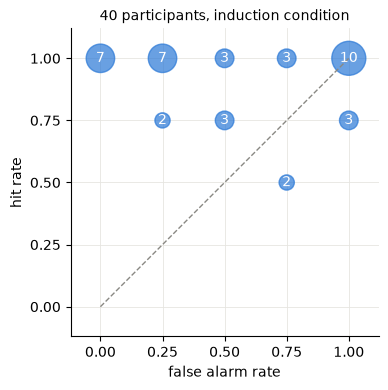

In [5]:
grid = np.arange(5)
count = np.zeros((5, 5), dtype=int)
np.add.at(count, (f, h), 1)
fa_grid, hit_grid = np.meshgrid(grid, grid, indexing="ij")

fig, ax = plt.subplots(figsize=(4.5, 4))
mask = count > 0
ax.scatter(
    fa_grid[mask] / 4, hit_grid[mask] / 4, s=60 * count[mask], color=BLUE, alpha=0.7
)
for i, j in zip(*np.nonzero(mask)):
    ax.text(i / 4, j / 4, count[i, j], ha="center", va="center", color="white")
ax.plot([0, 1], [0, 1], ls="--", color=GREY, lw=1)
ax.set(
    xlabel="false alarm rate",
    ylabel="hit rate",
    xlim=(-0.12, 1.12),
    ylim=(-0.12, 1.12),
    xticks=grid / 4,
    yticks=grid / 4,
    title=f"{k} participants, induction condition",
)
ax.set_aspect("equal")
plt.show()

Each circle shows the number of participants with these rates. A
participant on the dashed line cannot tell the signal from the noise.
30 of the 40 participants have 4 hits in 4 valid arguments. The false
alarms spread over the whole range: 13 participants say "valid" to all 4
invalid arguments. 10 participants are at the top right corner, on the
dashed line.

## The model

Participant $i$ has a discriminability $d_i$ and a bias $c_i$. The hit
rate and the false alarm rate follow from them:

$$\theta^h_i = \Phi\left(\tfrac{d_i}{2} - c_i\right), \qquad
\theta^f_i = \Phi\left(-\tfrac{d_i}{2} - c_i\right),$$

where $\Phi$ is the cumulative distribution function of the standard
Normal distribution. The hits and the false alarms are Binomial counts:
$h_i \sim \operatorname{Binomial}(\theta^h_i, s_i)$ and
$f_i \sim \operatorname{Binomial}(\theta^f_i, n_i)$.

The participants come from a group:

$$d_i \sim \operatorname{Normal}(\mu_d, 1/\sqrt{\lambda_d}), \qquad
c_i \sim \operatorname{Normal}(\mu_c, 1/\sqrt{\lambda_c}).$$

The group means $\mu_d$ (`mud`) and $\mu_c$ (`muc`) and the group
precisions $\lambda_d$ (`lambdad`) and $\lambda_c$ (`lambdac`) have
priors. The book gives the means a Normal prior with precision 0.001, and
the precisions a $\operatorname{Gamma}(0.001, 0.001)$ prior.

The PyMC model follows the rules of [Use a PyMC model][use-a-pymc-model]:
each input of a prior is a named `pm.Data` node. The model writes each
participant effect as the group mean plus a standard Normal draw times the
group standard deviation. This non-centered form gives the same model,
and PyMC samples it better.

In [6]:
BOOK_PRIOR = {
    "mud_mu": 0.0,
    "mud_sigma": 1 / np.sqrt(0.001),
    "muc_mu": 0.0,
    "muc_sigma": 1 / np.sqrt(0.001),
    "lambdad_alpha": 0.001,
    "lambdad_beta": 0.001,
    "lambdac_alpha": 0.001,
    "lambdac_beta": 0.001,
}


def phi(x: Any) -> Any:
    """Cumulative distribution function of the standard Normal distribution"""
    return 0.5 + 0.5 * pm.math.erf(x / np.sqrt(2))


with pm.Model() as model:
    data = {name: pm.Data(name, value) for name, value in BOOK_PRIOR.items()}
    mud = pm.Normal("mud", mu=data["mud_mu"], sigma=data["mud_sigma"])
    muc = pm.Normal("muc", mu=data["muc_mu"], sigma=data["muc_sigma"])
    lambdad = pm.Gamma(
        "lambdad", alpha=data["lambdad_alpha"], beta=data["lambdad_beta"]
    )
    lambdac = pm.Gamma(
        "lambdac", alpha=data["lambdac_alpha"], beta=data["lambdac_beta"]
    )

    # the participant effects, non-centered
    deltadi = pm.Normal("deltadi", mu=0.0, sigma=1.0, shape=k)
    deltaci = pm.Normal("deltaci", mu=0.0, sigma=1.0, shape=k)
    di = pm.Deterministic("di", mud + deltadi / pm.math.sqrt(lambdad))
    ci = pm.Deterministic("ci", muc + deltaci / pm.math.sqrt(lambdac))

    thetah = pm.Deterministic("hit_rate", phi(di / 2 - ci))
    thetaf = pm.Deterministic("fa_rate", phi(-di / 2 - ci))
    pm.Binomial("hi", p=thetah, n=s, observed=h)
    pm.Binomial("fi", p=thetaf, n=n, observed=f)

## From PyMC to TensorFlow

`adapter_pymc.parameters` lists the priors that `elicito` reads.
`adapter_pymc.model` returns the translated model. It returns each
observed variable and each `pm.Deterministic` by name: here `hi`, `fi`,
`di`, `ci`, `hit_rate` and `fa_rate`.

In [7]:
print([(p["name"], p["family"].__name__) for p in adapter_pymc.parameters(model)])

generative_model = adapter_pymc.model(model)()

[('mud', 'Normal'), ('muc', 'Normal'), ('lambdad', 'Gamma'), ('lambdac', 'Gamma')]


## Do the two models agree?

Both models get the same priors. The TensorFlow model and `pm.draw` each
draw 10 000 samples. If the translation is correct, the two samples come
from the same distribution.

The Kolmogorov-Smirnov (KS) distance $D$ measures the largest difference
between the two cumulative distributions. With 10 000 draws, a value
below 0.05 shows agreement. For each output, the table shows the largest
$D$ of the 40 participants.

Most draws of the book prior $\operatorname{Gamma}(0.001, 0.001)$ are
smaller than the smallest float32 number. The translated model computes
in float32, so $1/\sqrt{\lambda}$ is then infinite. The check therefore
uses $\operatorname{Gamma}(2, 2)$ for the two precisions. The translation
does not depend on these values.

In [8]:
CHECK_PRIOR = BOOK_PRIOR | {
    "mud_sigma": 1.0,
    "muc_sigma": 1.0,
    "lambdad_alpha": 2.0,
    "lambdad_beta": 2.0,
    "lambdac_alpha": 2.0,
    "lambdac_beta": 2.0,
}
pm.set_data(CHECK_PRIOR, model=model)


def sample_priors(pymc_model: Any, draws: int, seed: Any) -> Any:
    """Sample the priors of a PyMC model in TensorFlow, shape (1, draws, P)"""
    parameters = adapter_pymc.parameters(pymc_model)
    seeds = tfp.random.split_seed(seed, n=len(parameters))
    columns = []
    for parameter, param_seed in zip(parameters, seeds):
        args = {
            arg: float(pymc_model[hyper["name"]].get_value())
            for arg, hyper in parameter["hyperparams"].items()
        }
        columns.append(parameter["family"](**args).sample(draws, seed=param_seed))
    return tf.stack(columns, axis=-1)[None]


OUTPUTS = ("hit_rate", "fa_rate", "hi", "fi")
seed_priors, seed_model = tfp.random.split_seed(SEED)
prior_samples = sample_priors(model, DRAWS, seed_priors)
tf_out = generative_model(prior_samples, seed=seed_model)
pm_out = pm.draw([model[name] for name in OUTPUTS], draws=DRAWS, random_seed=1)

# float32 and float64 differ in the last digits: round both, in float64
samples = {
    name: {
        "TensorFlow": np.asarray(tf_out[name][0], dtype=float)
        .reshape(DRAWS, -1)
        .round(6),
        "PyMC": np.asarray(pm_values, dtype=float).reshape(DRAWS, -1).round(6),
    }
    for name, pm_values in zip(OUTPUTS, pm_out)
}
distance = {
    name: max(
        stats.ks_2samp(
            pair["TensorFlow"][:, j], pair["PyMC"][:, j], method="asymp"
        ).statistic
        for j in range(pair["PyMC"].shape[1])
    )
    for name, pair in samples.items()
}

print(f"{'output':<10}{'TensorFlow mean, sd':>22}{'PyMC mean, sd':>18}{'D':>8}")
for name, pair in samples.items():
    tf_stats, pm_stats = (
        f"{values.mean():.2f}, {values.std():.2f}" for values in pair.values()
    )
    print(f"{name:<10}{tf_stats:>22}{pm_stats:>18}{distance[name]:>8.3f}")
assert max(distance.values()) < TOL

output       TensorFlow mean, sd     PyMC mean, sd       D
hit_rate              0.50, 0.37        0.50, 0.37   0.020
fa_rate               0.50, 0.37        0.50, 0.37   0.021
hi                    1.99, 1.63        1.99, 1.63   0.013
fi                    2.00, 1.63        1.99, 1.63   0.016


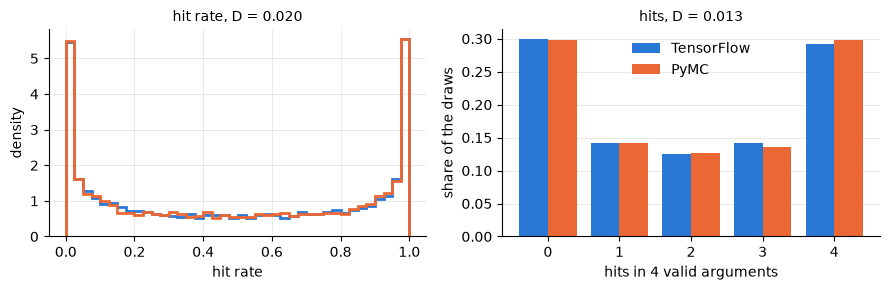

In [9]:
fig, (ax_rate, ax_hits) = plt.subplots(1, 2, figsize=(9, 3))

bins = np.linspace(0, 1, 41)
for (label, values), color in zip(samples["hit_rate"].items(), (BLUE, ORANGE)):
    ax_rate.hist(
        values[:, 0],
        bins,
        density=True,
        histtype="step",
        lw=2,
        color=color,
        label=label,
    )
ax_rate.set(
    xlabel="hit rate",
    ylabel="density",
    title=f"hit rate, D = {distance['hit_rate']:.3f}",
)

for offset, ((label, values), color) in zip(
    (-0.2, 0.2), zip(samples["hi"].items(), (BLUE, ORANGE))
):
    share = np.bincount(values[:, 0].astype(int), minlength=5) / DRAWS
    ax_hits.bar(grid + offset, share, width=0.4, color=color, label=label)
ax_hits.set(
    xlabel="hits in 4 valid arguments",
    ylabel="share of the draws",
    xticks=grid,
    title=f"hits, D = {distance['hi']:.3f}",
)
ax_hits.grid(axis="x", visible=False)
ax_hits.legend()
fig.tight_layout()
plt.show()

The figure shows participant 1. The distributions of the two models
overlap. Under the check prior, most hit rates are near 0 or near 1, so
0 and 4 hits are the most frequent counts.

## How fast is the translated model?

During the elicitation, `elicito` runs the model at each step of the
search. A fast model is therefore important. We time one forward pass of
10 000 samples. Each model runs once before the timing, so the time does
not include the compilation.

PyMC draws one sample per call of its compiled function. The TensorFlow
model draws all samples in one call.

In [10]:
REPEATS = 5

draw_pymc = pm.compile([], [model[name] for name in OUTPUTS], random_seed=1)


def run_pymc() -> None:
    """Draw DRAWS samples with the compiled PyMC function"""
    for _ in range(DRAWS):
        draw_pymc()


def run_tensorflow() -> None:
    """Draw DRAWS samples with the translated model"""
    out = generative_model(prior_samples, seed=seed_model)
    _ = [value.numpy() for value in out.values()]


seconds = {}
for label, run in (("TensorFlow", run_tensorflow), ("PyMC", run_pymc)):
    run()  # warm-up
    times = []
    for _ in range(REPEATS):
        start = time.perf_counter()
        run()
        times.append(time.perf_counter() - start)
    seconds[label] = float(np.median(times))

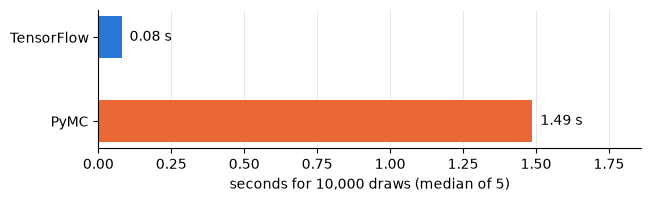

In [11]:
fig, ax = plt.subplots(figsize=(7, 1.8))
labels = list(seconds)
ax.barh(labels, list(seconds.values()), color=[BLUE, ORANGE], height=0.5)
for i, value in enumerate(seconds.values()):
    ax.text(value, i, f"  {value:.2f} s", va="center")
ax.set(
    xlabel=f"seconds for {DRAWS:,} draws (median of {REPEATS})",
    xlim=(0, 1.25 * max(seconds.values())),
)
ax.grid(axis="y", visible=False)
ax.invert_yaxis()
plt.show()

The translated model is 15 to 20 times faster. The exact times depend on
the computer and its load.

## Two simulated experts

A simulated expert answers with the quantiles that a chosen prior gives.
A real expert gives these quantiles directly.

| Expert | $\mu_d$ | $\mu_c$ | Description |
| :-- | :-- | :-- | :-- |
| A | Normal(1, 0.2) | Normal(-0.5, 0.2) | expects induction |
| B | Normal(2, 0.2) | Normal(0, 0.2) | expects deduction |

Both experts give the precisions the priors
$\lambda_d \sim \operatorname{Gamma}(20, 20)$ and
$\lambda_c \sim \operatorname{Gamma}(20, 5)$: a spread of about 1 in the
discriminability and of about 0.5 in the bias. Expert A expects the
behaviour of the induction condition: a low discriminability and a bias
to say "valid". Expert B expects the behaviour of the deduction
condition.

Each expert gives quantiles of four quantities:

- **hit rate:** "Of 100 valid arguments, how many does one person call valid?"
- **false alarm rate:** "Of 100 invalid arguments, how many does one person call
  valid?"
- **sd of hit rates:** "In a group of 40 people, how much do the hit rates differ?"
- **sd of false alarm rates:** "In a group of 40 people, how much do the false alarm
  rates differ?"

For the two standard deviations, an expert can also give a range: about
95 % of the group are within two standard deviations of the mean.

The expert answers each question with the 10 %, 25 %, 50 %, 75 % and
90 % quantiles. For the 10 % quantile, the question is: "Give a value
that is too low with a probability of 10 %."

The rates of one participant are not sufficient. Their spread has two
sources: the uncertainty about the group means $\mu$, and the
differences between the participants, $1/\sqrt{\lambda}$. The rates of one
participant cannot separate the two. The standard deviations of the group
describe the differences between the participants only.

In [12]:
EXPERTS = {
    "Expert A": {
        "mud": tfd.Normal(1.0, 0.2),
        "muc": tfd.Normal(-0.5, 0.2),
        "lambdad": tfd.Gamma(20.0, 20.0),
        "lambdac": tfd.Gamma(20.0, 5.0),
    },
    "Expert B": {
        "mud": tfd.Normal(2.0, 0.2),
        "muc": tfd.Normal(0.0, 0.2),
        "lambdad": tfd.Gamma(20.0, 20.0),
        "lambdac": tfd.Gamma(20.0, 5.0),
    },
}


def sd_hit_rate(hit_rate: Any) -> Any:
    """Return the standard deviation of the hit rates of the group"""
    return tf.math.reduce_std(hit_rate, axis=-1)


def sd_fa_rate(fa_rate: Any) -> Any:
    """Return the standard deviation of the false alarm rates of the group"""
    return tf.math.reduce_std(fa_rate, axis=-1)


PROBS = (0.1, 0.25, 0.5, 0.75, 0.9)
targets = [
    el.quantiles("hit rate", output="hit_rate", probs=PROBS),
    el.quantiles("false alarm rate", output="fa_rate", probs=PROBS),
    el.quantiles("sd of hit rates", output=sd_hit_rate, probs=PROBS),
    el.quantiles("sd of false alarm rates", output=sd_fa_rate, probs=PROBS),
]

In [13]:
fits = {}
for expert, ground_truth in EXPERTS.items():
    eliobj = el.Elicit(model, targets, seeds=(1, 2, 3), epochs=800, verbose=False)
    fits[expert] = eliobj.fit(
        el.expert.simulator(ground_truth=ground_truth, num_samples=10_000)
    )

## Did the elicitation succeed?

The loss must go down and level off. The elicited quantiles must be near
the quantiles of the expert: this is the check of the elicitation.

Different priors can give the same quantiles. The learned prior can
therefore differ from the prior of the simulated expert, and the
elicitation is still correct.

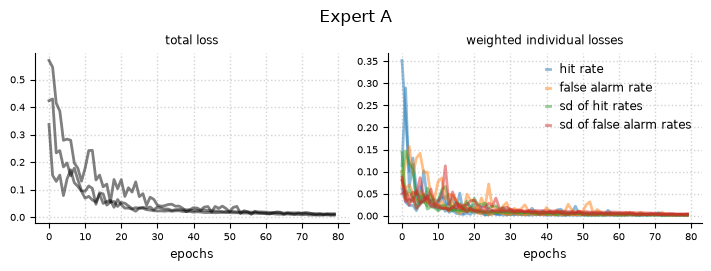

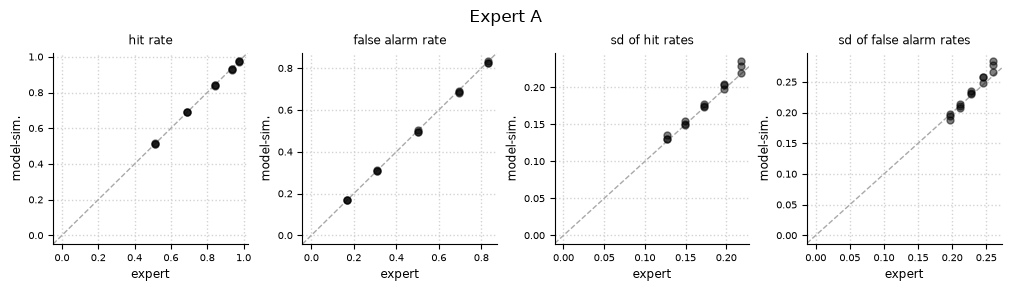

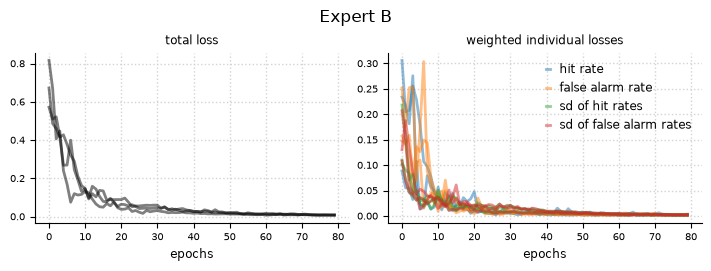

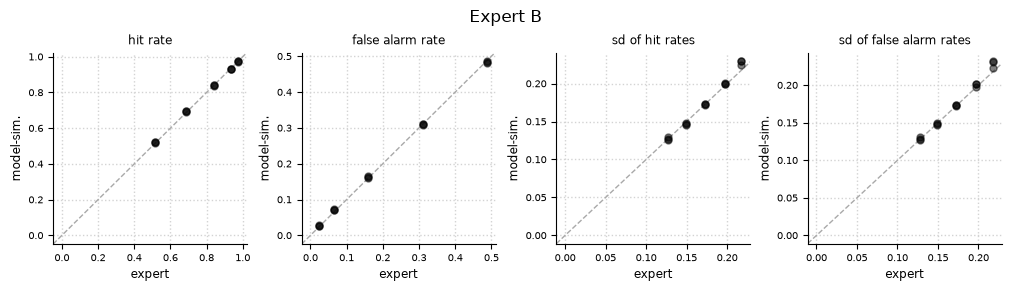

In [14]:
for expert, fit in fits.items():
    fig, _ = fit.plot.loss(figsize=(7, 2.6))
    fig.suptitle(expert)
    plt.show()
    fig, _ = fit.plot.elicits(cols=4, figsize=(10, 2.8))
    fig.suptitle(expert)
    plt.show()

## From prior to posterior

We now give each elicited prior back to the PyMC model with
`pm.set_data`. PyMC then fits the model to the data. The book prior is
the reference. We use the replication with the lowest loss.

In [15]:
PRIORS = {"Book": BOOK_PRIOR}
PRIORS |= {expert: fit.hyperparameters() for expert, fit in fits.items()}

for label, prior in PRIORS.items():
    print(f"{label:<10}" + "  ".join(f"{k} {v:.2f}" for k, v in prior.items()))

Book      mud_mu 0.00  mud_sigma 31.62  muc_mu 0.00  muc_sigma 31.62  lambdad_alpha 0.00  lambdad_beta 0.00  lambdac_alpha 0.00  lambdac_beta 0.00
Expert A  lambdac_alpha 14.18  lambdad_alpha 4.05  muc_mu -0.49  mud_mu 1.01  lambdac_beta 6.66  lambdad_beta 0.39  muc_sigma 0.01  mud_sigma 0.30
Expert B  lambdac_alpha 7.33  lambdad_alpha 5.77  muc_mu 0.00  mud_mu 1.97  lambdac_beta 2.44  lambdad_beta 2.84  muc_sigma 0.16  mud_sigma 0.06


In [16]:
PARAMETERS = ("mud", "muc")

posteriors, predictives = {}, {}
for label, prior in PRIORS.items():
    with model:
        pm.set_data(prior)
        idata = pm.sample(1000, tune=1000, chains=4, random_seed=1, progressbar=True)
        pm.sample_posterior_predictive(
            idata, extend_inferencedata=True, random_seed=1, progressbar=False
        )
    posteriors[label] = idata
    predictives[label] = idata.posterior_predictive

print(
    f"{'prior':<10}{'parameter':<10}{'mean':>6}{'90 % interval':>16}{'divergences':>13}"
)
for label, idata in posteriors.items():
    divergences = int(idata.sample_stats["diverging"].sum())
    for name in PARAMETERS:
        values = idata.posterior[name].values.ravel()
        low, high = np.quantile(values, [0.05, 0.95])
        print(
            f"{label:<10}{name:<10}{values.mean():>6.2f}"
            f"{f'{low:.2f}, {high:.2f}':>16}{divergences:>13}"
        )

Output()

There were 45 divergences after tuning. Increase `target_accept` or reparameterize.


Output()

Output()

prior     parameter   mean   90 % interval  divergences
Book      mud         1.90      1.24, 2.65           45
Book      muc        -1.15    -1.49, -0.85           45
Expert A  mud         1.28      1.01, 1.56            0
Expert A  muc        -0.49    -0.50, -0.48            0
Expert B  mud         1.95      1.85, 2.04            0
Expert B  muc        -0.56    -0.73, -0.37            0


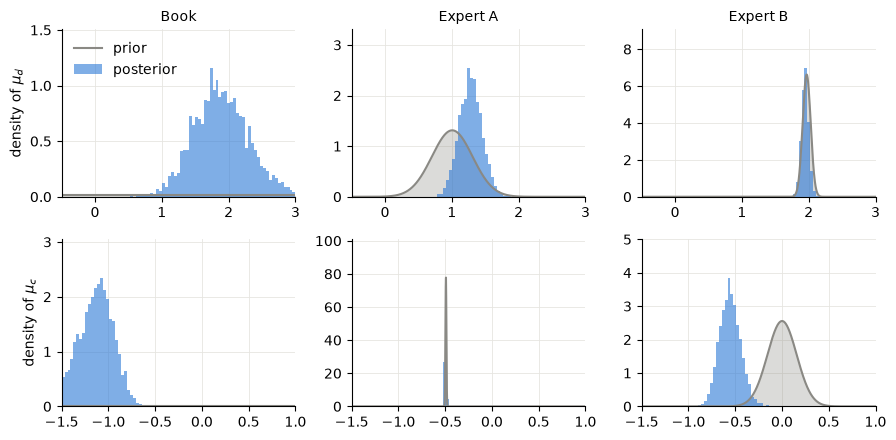

In [17]:
X_RANGE = {"mud": (-0.5, 3.0), "muc": (-1.5, 1.0)}
SYMBOL = {"mud": r"$\mu_d$", "muc": r"$\mu_c$"}

fig, axs = plt.subplots(len(PARAMETERS), len(PRIORS), figsize=(9, 4.5), sharex="row")
for row, name in enumerate(PARAMETERS):
    x_grid = np.linspace(*X_RANGE[name], 1000)
    for col, (label, prior) in enumerate(PRIORS.items()):
        ax = axs[row, col]
        density = stats.norm(prior[f"{name}_mu"], prior[f"{name}_sigma"]).pdf(x_grid)
        ax.fill_between(x_grid, density, color=GREY, alpha=0.3, lw=0)
        ax.plot(x_grid, density, color=GREY, lw=1.5, label="prior")
        heights, *_ = ax.hist(
            posteriors[label].posterior[name].values.ravel(),
            bins=np.linspace(*X_RANGE[name], 80),
            density=True,
            histtype="stepfilled",
            color=BLUE,
            alpha=0.6,
            label="posterior",
        )
        ax.set(xlim=X_RANGE[name], ylim=(0, 1.3 * max(heights.max(), density.max())))
        if row == 0:
            ax.set_title(label)
        if col == 0:
            ax.set_ylabel(f"density of {SYMBOL[name]}")
axs[0, 0].legend()
fig.tight_layout()
plt.show()

- **Book prior.** The posterior of $\mu_d$ has the mean 1.90 (90 %
  interval 1.24 to 2.65), and the posterior of $\mu_c$ the mean -1.15: a
  strong bias to say "valid". With the vague book prior, PyMC reports 45
  divergences. The expert priors give none.
- **Expert A.** The elicited prior of $\mu_d$ is Normal(1.01, 0.30), a
  little wider than the prior of the expert, Normal(1, 0.2). The
  posterior of $\mu_d$ moves to the mean 1.28. The elicited prior of
  $\mu_c$ is Normal(-0.49, 0.01). It is much narrower than the prior of
  the expert, Normal(-0.5, 0.2). The posterior stays at the prior: mean
  -0.49.
- **Expert B.** The elicited prior of $\mu_d$ is Normal(1.97, 0.06). It
  is narrower than the prior of the expert, Normal(2, 0.2), but it
  agrees with the data. The posterior has the mean 1.95, near the book
  posterior. The posterior of $\mu_c$ moves from the prior mean 0.00 to
  -0.56.


## Does the model fit the data?

A posterior predictive check simulates new data from the fitted model,
once for each posterior draw. The figure repeats the first figure, with
one panel for each prior.

The dots count the participants with each number of hits and false
alarms. A line is the 90 % interval of the simulated counts.

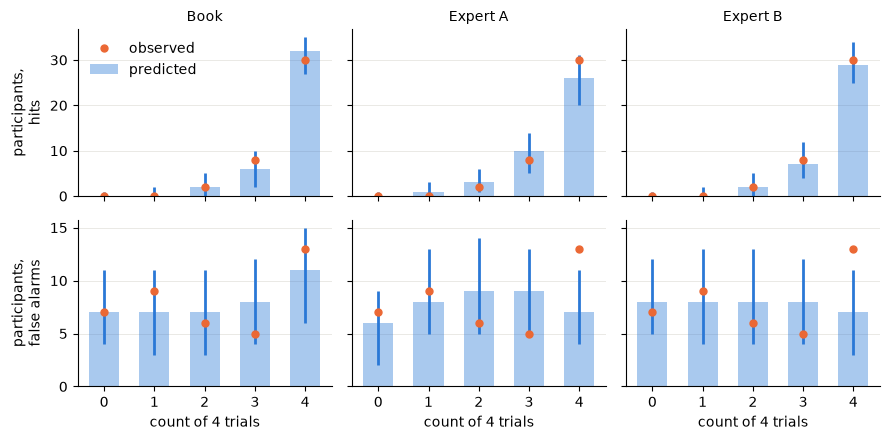

In [18]:
fig, axs = plt.subplots(2, len(PRIORS), figsize=(9, 4.5), sharex=True, sharey="row")
for col, (label, predictive) in enumerate(predictives.items()):
    for row, (name, observed, what) in enumerate(
        (("hi", h, "hits"), ("fi", f, "false alarms"))
    ):
        ax = axs[row, col]
        rep = predictive[name].values.reshape(-1, k)
        counts = (rep[:, :, None] == grid).sum(axis=1)
        low, mid, high = np.quantile(counts, [0.05, 0.5, 0.95], axis=0)
        ax.bar(grid, mid, color=BLUE, alpha=0.4, width=0.6, label="predicted")
        ax.vlines(grid, low, high, color=BLUE, lw=2)
        ax.plot(
            grid,
            np.bincount(observed, minlength=5),
            "o",
            color=ORANGE,
            ms=5,
            label="observed",
        )
        ax.grid(axis="x", visible=False)
        if row == 0:
            ax.set_title(label)
        else:
            ax.set_xlabel("count of 4 trials")
        if col == 0:
            ax.set_ylabel(f"participants,\n{what}")
axs[0, 0].legend()
fig.tight_layout()
plt.show()

With the book prior, all observed counts are inside the 90 % intervals.
With both expert priors, the 13 participants with 4 false alarms are
above the interval. Both expert priors keep $\mu_c$ near -0.5, but the
data need a stronger bias: the book posterior is -1.15. With expert A,
the model also predicts too few participants with 4 hits: a median of
about 26 against 30 observed, at the edge of the interval.

## Takeaways

- **Translation.** One call translates the PyMC model. The largest KS
  distance of the four outputs is 0.021.
- **Speed.** The translated model is 15 to 20 times faster than PyMC.
- **Elicitation.** Check the elicited quantiles against the quantiles of
  the expert. Then look at the elicited prior itself: it can be much
  narrower than the prior of the expert, and still give the same
  quantiles.
- **Posterior predictive check.** A prior that is too narrow holds the
  posterior. The posterior predictive check shows the misfit.

## Appendix

The PyMC3 model comes from the notebook
[SignalDetectionTheory.ipynb](https://github.com/pymc-devs/pymc-resources/blob/main/BCM/CaseStudies/SignalDetectionTheory.ipynb)
of pymc-resources (MIT licence). See the [case studies](index.md) for the
credit.

In [19]:
import importlib.metadata
import sys

print(f"Python {sys.version.split()[0]}")
for package in ("elicito", "pymc", "tensorflow", "tensorflow-probability"):
    print(f"{package} {importlib.metadata.version(package)}")

Python 3.13.13
elicito 0.7.1a1
pymc 6.3.2
tensorflow 2.20.0
tensorflow-probability 0.25.0


## References

- Heit, E., & Rotello, C. M. (2005). Are there two kinds of reasoning? In
  *Proceedings of the 27th Annual Meeting of the Cognitive Science Society*
  (pp. 923-928).
- Lee, M. D., & Wagenmakers, E.-J. (2013). *Bayesian Cognitive Modeling: A
  Practical Course*. Cambridge University Press.